In [3]:
import json
import os
import sys
from pathlib import Path

def locate_project_root(start=Path.cwd()):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'tutorial' / 'inlist_project').is_file():
            return candidate
    raise FileNotFoundError('Could not locate tutorial/inlist_project')

PROJECT_ROOT = locate_project_root()
PIPELINE_DIR = PROJECT_ROOT / 'scripts' / 'mams_profiles' / 'pipeline'
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

from mams_pipeline import (
    build_configs, inspect_runs, model_label, prepare_grid,
    render_inlist_project, run_local, submit_slurm,
)

print(f'Project root: {PROJECT_ROOT}')

# Main user-editable parameters
MASSES_MSUN = [2]
INITIAL_Y = 0.2703
INITIAL_Z = 0.0142
CENTRAL_H1_LIMIT = 0.01

# Slurm settings used only if SUBMIT_SLURM is enabled.
PARTITION = 'typhon'
WALLTIME = '7-00:00:00'
CPUS_PER_TASK = 1

# An environment override makes validation and alternate output locations easy.
OUTPUT_ROOT = Path(os.environ.get(
    'MAMS_OUTPUT_ROOT', PROJECT_ROOT / 'results' / 'mams_profiles'
)).resolve()
TEMPLATE_DIR = PROJECT_ROOT / 'tutorial'
OVERWRITE = True
PREPARE_RUNS = True
RUN_LOCAL = True       # Runs models sequentially and waits; potentially slow.
SUBMIT_SLURM = False    # Submits all prepared models and returns job IDs.

if RUN_LOCAL and SUBMIT_SLURM:
    raise ValueError('Choose local execution or Slurm submission, not both.')


configs = build_configs(
    MASSES_MSUN,
    initial_y=INITIAL_Y,
    initial_z=INITIAL_Z,
    central_h1_limit=CENTRAL_H1_LIMIT,
    partition=PARTITION,
    walltime=WALLTIME,
    cpus_per_task=CPUS_PER_TASK,
)

for config in configs:
    print(f'{config.mass_msun:8g} M_sun  ->  {model_label(config.mass_msun)}')

template_text = (TEMPLATE_DIR / 'inlist_project').read_text()
preview = render_inlist_project(template_text, configs[0])
keys_to_show = (
    'filename_for_profile_when_terminate', 'save_pulse_data_filename',
    'initial_mass', 'initial_y', 'initial_z', 'Zbase',
    'xa_central_lower_limit(1)',
)
for line in preview.splitlines():
    if any(key in line for key in keys_to_show):
        print(line)

assert f"'{model_label(configs[0].mass_msun)}.profile'" in preview
assert f"'{model_label(configs[0].mass_msun)}.mesa'" in preview
print('In-memory smoke test passed.')

runs = []
if PREPARE_RUNS:
    runs = prepare_grid(
        configs, TEMPLATE_DIR, OUTPUT_ROOT, overwrite=OVERWRITE
    )
    print(f'Prepared {len(runs)} run(s) under {OUTPUT_ROOT}')
else:
    print('PREPARE_RUNS is false; no directories were written.')

inspect_runs(runs)

job_ids = {}
if RUN_LOCAL:
    for run in runs:
        print(f'Running {run.label} ...', flush=True)
        run_local(run)
elif SUBMIT_SLURM:
    for run in runs:
        job_ids[run.label] = submit_slurm(run)
    print(json.dumps(job_ids, indent=2))
else:
    print('Setup only: no MESA processes or Slurm jobs were started.')

status = inspect_runs(runs)
print(json.dumps(status, indent=2))

if runs:
    metadata = json.loads(runs[0].metadata_path.read_text())
    print('\nFirst run metadata:')
    print(json.dumps(metadata, indent=2))

    if runs[0].gyre_path.is_file():
        fields = runs[0].gyre_path.read_text().splitlines()[0].split()
        names = ['zones', 'mass_g', 'radius_cm', 'luminosity_erg_s', 'version']
        print('\nGYRE header:', dict(zip(names, fields)))

Project root: /Users/mchau/mesa_tutorial
       2 M_sun  ->  MAMS2Msun
   filename_for_profile_when_terminate = 'MAMS2Msun.profile'
   save_pulse_data_filename = 'MAMS2Msun.mesa'
   initial_mass = 2
   initial_y = 0.2703  ! Helium mass fraction
   initial_z = 0.0142  ! Metal mass fraction, hydrogen = 1 - metal - helium
   xa_central_lower_limit(1) = 0.01
  use_Zbase_for_Type1 = .true.
  Zbase = 0.0142
In-memory smoke test passed.
Prepared 1 run(s) under /Users/mchau/mesa_tutorial/results/mams_profiles
Running MAMS2Msun ...
[
  {
    "label": "MAMS2Msun",
    "prepared": true,
    "mesa_profile": true,
    "gyre_model": true,
    "run_dir": "/Users/mchau/mesa_tutorial/results/mams_profiles/MAMS2Msun"
  }
]

First run metadata:
{
  "config": {
    "central_h1_limit": 0.01,
    "cpus_per_task": 1,
    "initial_y": 0.2703,
    "initial_z": 0.0142,
    "mass_msun": 2,
    "partition": "typhon",
    "walltime": "7-00:00:00"
  },
  "gyre_filename": "MAMS2Msun.mesa",
  "label": "MAMS2Msun",
  

In [5]:
!pip install mesa-reader

In [2]:
import sys
print(sys.executable)

/Users/mchau/mesa_tutorial/.venv/bin/python


In [3]:
import sys
!{sys.executable} -m pip install mesa-reader

  Using cached mesa_reader-0.4.0-py3-none-any.whl.metadata (2.7 kB)
Using cached mesa_reader-0.4.0-py3-none-any.whl (27 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 68.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 62.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mesa-reader] 1/3 [pandas]


In [1]:
from mesa_reader import MesaData
print("mesa_reader works!")

mesa_reader works!


In [5]:
import pandas as pd

file = "/Users/mchau/mesa_tutorial/results/mams_profiles/MAMS2Msun/MAMS2Msun.profile"

profile = pd.read_csv(
    file,
    sep=r"\s+",
    skiprows=5
)

profile.head()

,zone,mass,logR,logT,logRho,logP,x_mass_fraction_H,y_mass_fraction_He,z_mass_fraction_metals,pp,cno,tri_alpha
0,1,2.0,0.444883,3.896485,-8.309627,3.414879,0.7155,0.2703,0.0142,1.698628e-28,0.0,0.0
1,2,2.0,0.444881,3.897984,-8.299869,3.426502,0.7155,0.2703,0.0142,1.739518e-28,0.0,0.0
2,3,2.0,0.444874,3.899797,-8.289218,3.439443,0.7155,0.2703,0.0142,1.782708e-28,0.0,0.0
3,4,2.0,0.444870,3.902125,-8.276684,3.454963,0.7155,0.2703,0.0142,1.834911e-28,0.0,0.0
4,5,2.0,0.444862,3.905152,-8.262767,3.472850,0.7155,0.2703,0.0142,1.894667e-28,0.0,0.0


In [6]:
profile.columns

Index(['zone', 'mass', 'logR', 'logT', 'logRho', 'logP', 'x_mass_fraction_H',
       'y_mass_fraction_He', 'z_mass_fraction_metals', 'pp', 'cno',
       'tri_alpha'],
      dtype='str')

In [7]:
profile.shape

(902, 12)

In [9]:
import sys
!{sys.executable} -m pip install matplotlib numpy

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 38.6 MB/s  0:00:00 38.4 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 38.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 67.0 MB/s  0:00:00
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]


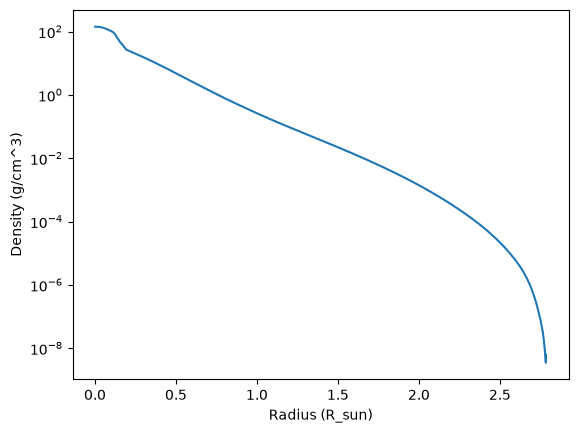

In [13]:
radius = 10**profile["logR"]   # radius in solar radii
rho = 10**profile["logRho"]    # density in g/cm^3

plt.plot(radius, rho)
plt.yscale("log")
plt.xlabel("Radius (R_sun)")
plt.ylabel("Density (g/cm^3)")
plt.show()

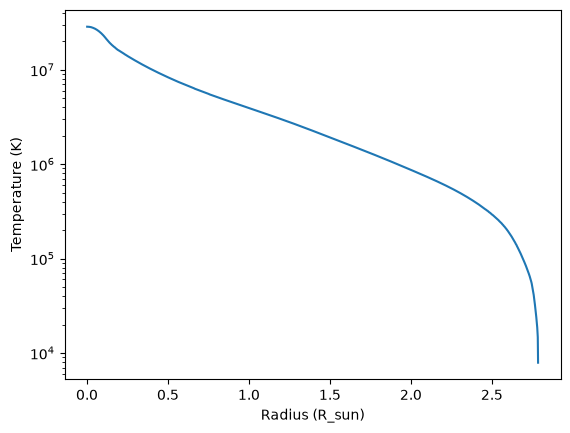

In [14]:
T = 10**profile["logT"]

plt.plot(radius, T)
plt.yscale("log")
plt.xlabel("Radius (R_sun)")
plt.ylabel("Temperature (K)")
plt.show()

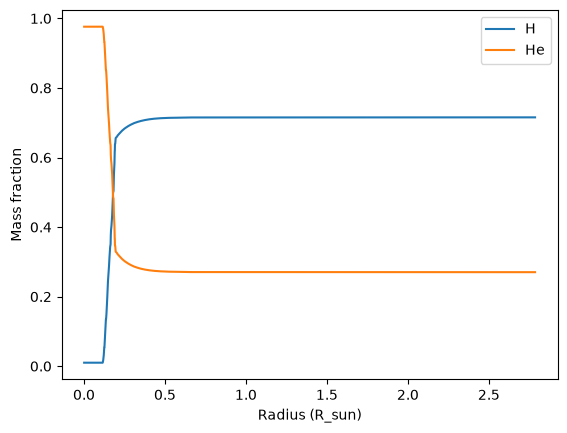

In [15]:
plt.plot(radius, profile["x_mass_fraction_H"], label="H")
plt.plot(radius, profile["y_mass_fraction_He"], label="He")

plt.xlabel("Radius (R_sun)")
plt.ylabel("Mass fraction")
plt.legend()
plt.show()

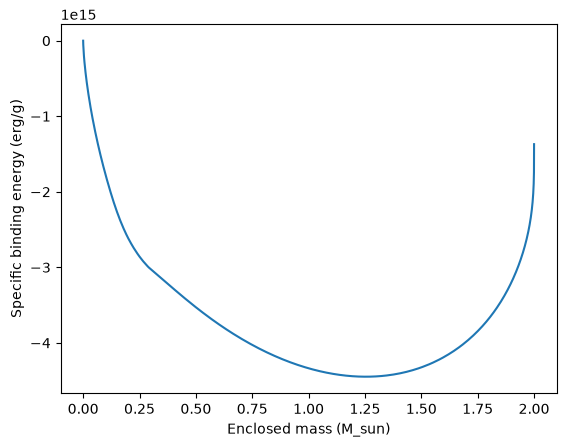

In [16]:
import numpy as np

G = 6.6743e-8
M = profile["mass"] * 1.9885e33
R = 10**profile["logR"] * 6.957e10

binding_energy = -G*M/R

plt.plot(profile["mass"], binding_energy)

plt.xlabel("Enclosed mass (M_sun)")
plt.ylabel("Specific binding energy (erg/g)")
plt.show()